# Task 1: N-Queens -- Propositional Logic (PySAT) and Local Search (Min-Conflicts)

This notebook presents the Propositional Logic (CNF) formulation of the $N$-Queens problem, describes the constraint-discovery algorithm and PySAT (`Glucose3`) encoding implemented in `n_queens_solver.py`, introduces the custom Min-Conflicts variable selection and initialization heuristic, and evaluates both approaches experimentally across increasing board sizes $N$.

## Section 1: Propositional Logic Formulation and CNF Encoding

Given an $N \times N$ chessboard with 0-indexed rows $r \in \{0, \dots, N-1\}$ and columns $c \in \{0, \dots, N-1\}$:

1. **Boolean Variables ($N^2$ variables):** Each square $(r, c)$ is assigned a propositional variable $X_{r,c} \in \{\text{True}, \text{False}\}$, mapped bijectively to a 1-indexed DIMACS SAT integer ID:
   $$\text{var\_id}(r, c) = r \cdot N + c + 1 \in \{1, 2, \dots, N^2\}$$
   $X_{r,c} = \text{True}$ means a queen occupies square $(r, c)$, and $X_{r,c} = \text{False}$ means $(r, c)$ is empty.

2. **Constraint Discovery & CNF Clause Conversion:** A valid $N$-Queens placement requires four families of constraints, each directly expressible in Conjunctive Normal Form (CNF):
   - **At-least-one queen per column ($N$ clauses of length $N$):**
     $$\bigwedge_{c=0}^{N-1} \left( \bigvee_{r=0}^{N-1} X_{r,c} \right)$$
   - **At-most-one queen per column ($N \binom{N}{2}$ binary clauses):**
     $$\bigwedge_{c=0}^{N-1} \bigwedge_{0 \le r_1 < r_2 < N} (\neg X_{r_1,c} \lor \neg X_{r_2,c})$$
   - **At-most-one queen per row ($N \binom{N}{2}$ binary clauses):**
     $$\bigwedge_{r=0}^{N-1} \bigwedge_{0 \le c_1 < c_2 < N} (\neg X_{r,c_1} \lor \neg X_{r,c_2})$$
   - **At-most-one queen per diagonal ($2 \sum_{k=2}^{N} \binom{k}{2} - \binom{N}{2} = \frac{N(N-1)(2N-1)}{3} - \binom{N}{2}$ binary clauses):**
     For every pair $(r_1, c_1)$ and $(r_2, c_2)$ with $r_1 < r_2$ and $|r_1 - r_2| = |c_1 - c_2|$:
     $$(\neg X_{r_1,c_1} \lor \neg X_{r_2,c_2})$$

3. **Total Exact Clause Count:** Summing all four groups gives:
   $$|C(N)| = N + 2 N \binom{N}{2} + \frac{(N-1)N(2N-1)}{3} = \frac{5N^3 - 6N^2 + 4N}{3}$$
   For example, $N = 4$ yields $80$ clauses and $N = 8$ yields $736$ clauses. Optional pre-placed queens at $(r, c)$ simply append unit clauses $(X_{r,c})$.

N= 4: vars= 16, clauses=  80 (formula=  80), solved=True, valid=True, time=0.4777 ms, board=[1, 3, 0, 2]
N= 8: vars= 64, clauses= 736 (formula= 736), solved=True, valid=True, time=3.5218 ms, board=[7, 2, 0, 5, 1, 4, 6, 3]
N=12: vars=144, clauses=2608 (formula=2608), solved=True, valid=True, time=7.3468 ms, board=[9, 5, 8, 10, 0, 2, 6, 1, 3, 7, 11, 4]


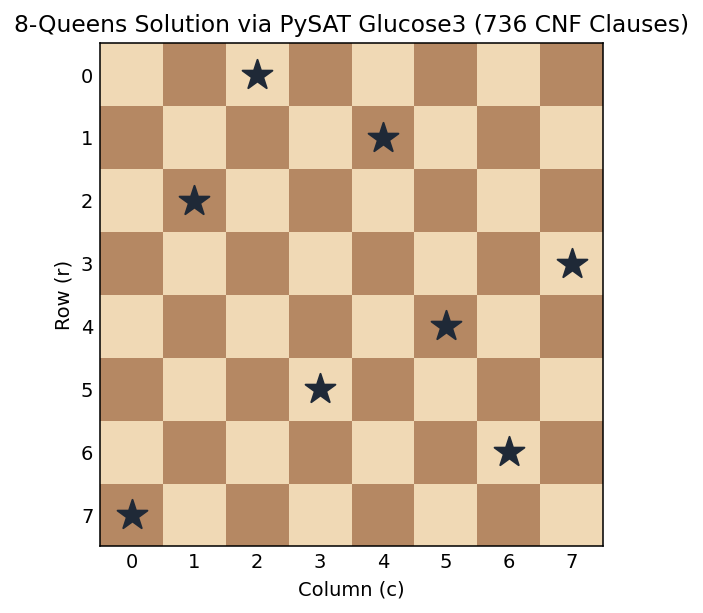

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "Task1" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from Task1.n_queens_solver import NQueenBoard, NQueenSolver

for n in (4, 8, 12):
    solver = NQueenSolver(n)
    res = solver.solve_pysat()
    expected_clauses = (5 * n**3 - 6 * n**2 + 4 * n) // 3
    valid = solver.board_helper.is_valid_solution(res["board"])
    print(
        f"N={n:>2}: vars={res['num_variables']:>3}, "
        f"clauses={res['num_clauses']:>4} (formula={expected_clauses:>4}), "
        f"solved={res['solved']}, valid={valid}, "
        f"time={res['runtime_ms']:.4f} ms, board={res['board']}"
    )

# Visualize the N=8 PySAT solution
res_8 = NQueenSolver(8).solve_pysat()
board_8 = res_8["board"]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
for r in range(8):
    for c in range(8):
        color = "#F0D9B5" if (r + c) % 2 == 0 else "#B58863"
        ax.add_patch(plt.Rectangle((c, 7 - r), 1, 1, facecolor=color))
        if board_8[c] == r:
            ax.scatter(c + 0.5, 7 - r + 0.5, s=260, c="#1F2937", marker="*", zorder=3)
ax.set_xlim(0, 8)
ax.set_ylim(0, 8)
ax.set_xticks([c + 0.5 for c in range(8)])
ax.set_xticklabels(range(8))
ax.set_yticks([7 - r + 0.5 for r in range(8)])
ax.set_yticklabels(range(8))
ax.tick_params(length=0)
ax.set_xlabel("Column (c)")
ax.set_ylabel("Row (r)")
ax.set_title("8-Queens Solution via PySAT Glucose3 (736 CNF Clauses)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## Section 2: PySAT (Glucose3) Scaling Experiments ($N = 4 \dots 30$)

We run the CDCL SAT solver `Glucose3` across increasing board sizes $N \in [4, 30]$ and record the number of propositional variables ($N^2$), total CNF clauses ($O(N^3)$), and solver wall-clock runtime (`runtime_ms`).

Loaded 27 PySAT benchmark rows from task1_pysat_benchmark.csv (N=4..30)


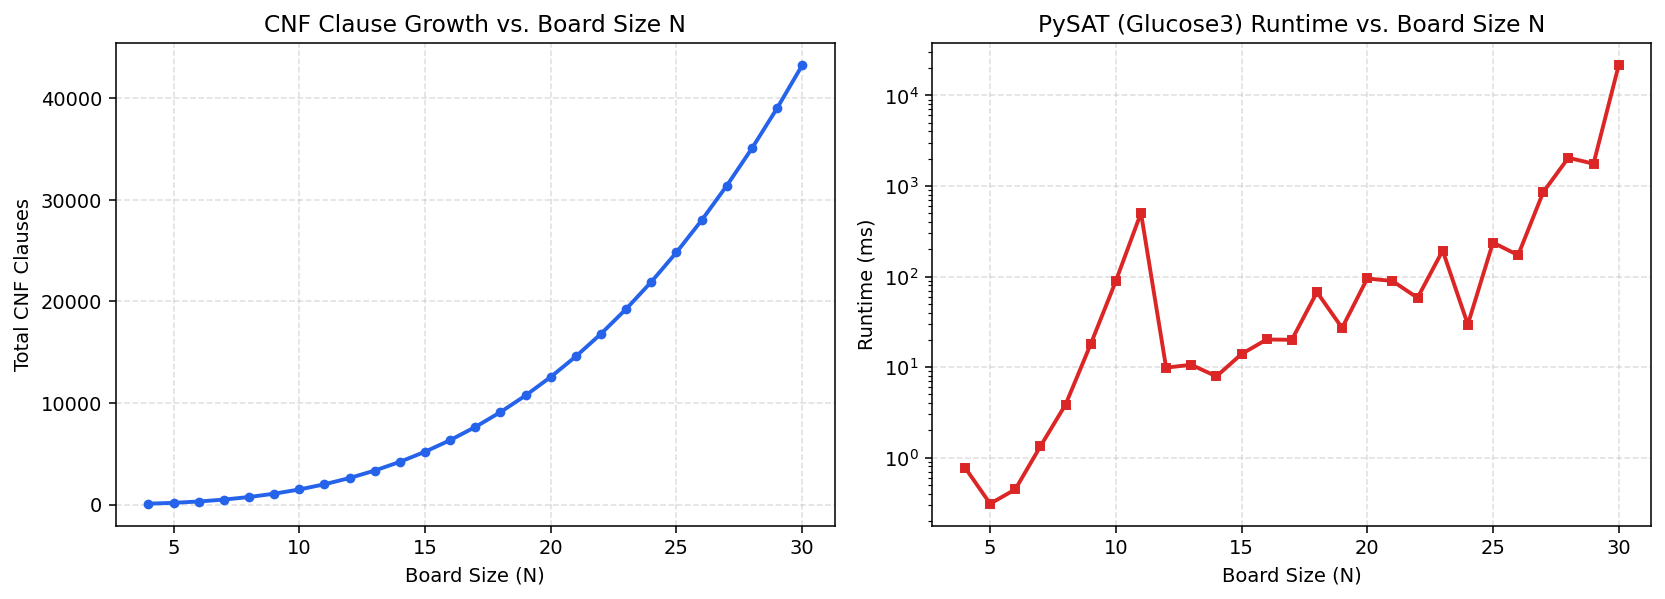

,N,num_variables,num_clauses,runtime_ms
0,4,16,80,0.7768
1,5,25,165,0.3097
2,6,36,296,0.4456
3,7,49,483,1.3333
4,8,64,736,3.8493
5,9,81,1065,17.8911
6,10,100,1480,89.0463
7,11,121,1991,503.5995
8,12,144,2608,9.8529
9,13,169,3341,10.5945


In [2]:
from Task1.run_benchmarks import run_pysat_benchmarks, run_min_conflicts_benchmarks

pysat_csv = ROOT / "Task1" / "task1_pysat_benchmark.csv"
if not pysat_csv.exists():
    run_pysat_benchmarks(list(range(4, 31)), output_csv=str(pysat_csv))

df_pysat = pd.read_csv(pysat_csv)
print(f"Loaded {len(df_pysat)} PySAT benchmark rows from {pysat_csv.name} (N={df_pysat['N'].min()}..{df_pysat['N'].max()})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
ax1.plot(df_pysat["N"], df_pysat["num_clauses"], marker="o", markersize=4, color="#2563EB", linewidth=2)
ax1.set_title("CNF Clause Growth vs. Board Size N")
ax1.set_xlabel("Board Size (N)")
ax1.set_ylabel("Total CNF Clauses")
ax1.grid(True, linestyle="--", alpha=0.4)

ax2.plot(df_pysat["N"], df_pysat["runtime_ms"], marker="s", markersize=4, color="#DC2626", linewidth=2)
ax2.set_title("PySAT (Glucose3) Runtime vs. Board Size N")
ax2.set_xlabel("Board Size (N)")
ax2.set_ylabel("Runtime (ms)")
ax2.set_yscale("log")
ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

df_pysat

## Section 3: Min-Conflicts Local Search and Proposed Variable-Selection Heuristic

### Standard Min-Conflicts vs. Proposed Custom Heuristic

Both variants store the board as a 1D permutation-free column assignment `board[col] = row` (one queen per column) and maintain $O(1)$ incremental conflict counters (`row_counts`, `diag1_counts`, `diag2_counts`):

1. **Standard Min-Conflicts:**
   - Initializes each column's queen to a uniformly random row.
   - At each step, picks a **uniformly random** conflicted column and moves its queen to the row minimizing conflicts (random tie-break).
2. **Proposed Custom Heuristic Min-Conflicts (`MinConflicts_Custom`):**
   - **Greedy Min-Conflict Initialization:** Places queens column-by-column into a row that immediately minimizes conflicts with previously placed columns, drastically lowering initial conflicts before search begins.
   - **Max-Conflicts Variable Selection with Tabu Tenure:** Rather than repairing a random conflicted column, selects the column suffering the **highest number of conflicts** (skipping columns moved within a short tabu tenure $\max(1, \min(4, \lfloor N/4 \rfloor))$), eliminating the worst bottleneck queens first while preventing 2-cycle oscillations.
   - **Move-Forcing Tie-Break & Random Restarts:** Avoids staying on the current row when multiple rows tie for minimum conflicts, and triggers clean restarts if a plateau exceeds $\max(100, 15N)$ steps.

N=  4 | Standard:  11.55 steps ( 0.1165 ms) | Custom:  2.60 steps ( 0.0624 ms) | Steps Reduced:  4.44x | Speedup: 1.87x
N=  8 | Standard: 139.20 steps ( 1.4143 ms) | Custom: 14.65 steps ( 0.2361 ms) | Steps Reduced:  9.50x | Speedup: 5.99x
N= 16 | Standard:  91.20 steps ( 1.5826 ms) | Custom: 16.70 steps ( 0.3527 ms) | Steps Reduced:  5.46x | Speedup: 4.49x
N= 32 | Standard:  84.00 steps ( 3.1244 ms) | Custom: 26.80 steps ( 1.2830 ms) | Steps Reduced:  3.13x | Speedup: 2.44x
N= 50 | Standard: 107.95 steps ( 5.7188 ms) | Custom: 32.10 steps ( 2.2740 ms) | Steps Reduced:  3.36x | Speedup: 2.51x
N=100 | Standard: 145.80 steps (13.7788 ms) | Custom: 27.85 steps ( 5.1011 ms) | Steps Reduced:  5.24x | Speedup: 2.70x
N=200 | Standard: 204.50 steps (39.0830 ms) | Custom: 22.90 steps (14.7112 ms) | Steps Reduced:  8.93x | Speedup: 2.66x


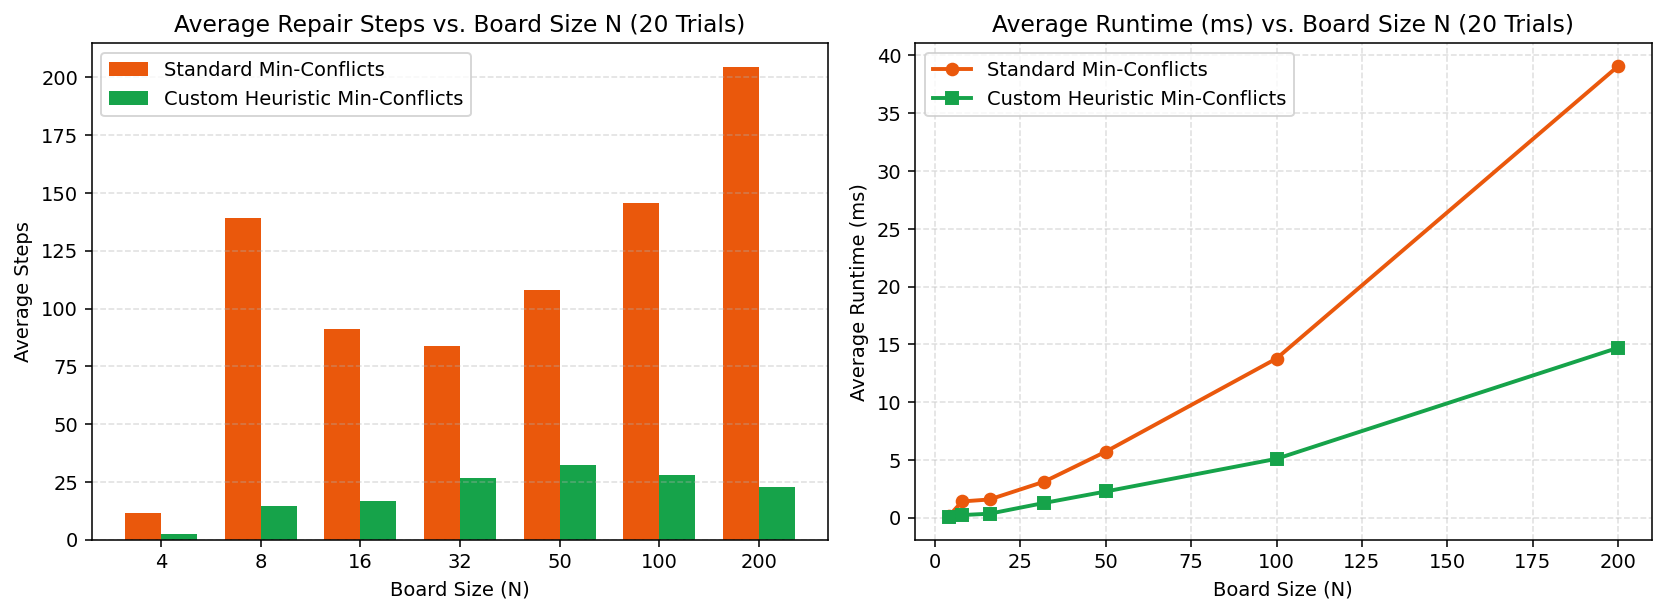

,N,variant,avg_steps,avg_runtime_ms,success_rate
0,4,MinConflicts_Standard,11.55,0.1165,1.0
1,4,MinConflicts_Custom,2.60,0.0624,1.0
2,8,MinConflicts_Standard,139.20,1.4143,1.0
3,8,MinConflicts_Custom,14.65,0.2361,1.0
4,16,MinConflicts_Standard,91.20,1.5826,1.0
5,16,MinConflicts_Custom,16.70,0.3527,1.0
6,32,MinConflicts_Standard,84.00,3.1244,1.0
7,32,MinConflicts_Custom,26.80,1.2830,1.0
8,50,MinConflicts_Standard,107.95,5.7188,1.0
9,50,MinConflicts_Custom,32.10,2.2740,1.0


In [3]:
mc_csv = ROOT / "Task1" / "task1_min_conflicts_benchmark.csv"
if not mc_csv.exists():
    run_min_conflicts_benchmarks(
        [4, 8, 16, 32, 50, 100, 200], trials=20, max_steps=10000, output_csv=str(mc_csv)
    )

df_mc = pd.read_csv(mc_csv)
df_std = df_mc[df_mc["variant"] == "MinConflicts_Standard"].sort_values("N")
df_cst = df_mc[df_mc["variant"] == "MinConflicts_Custom"].sort_values("N")

for _, r_s in df_std.iterrows():
    r_c = df_cst[df_cst["N"] == r_s["N"]].iloc[0]
    step_ratio = r_s["avg_steps"] / max(1e-6, r_c["avg_steps"])
    time_ratio = r_s["avg_runtime_ms"] / max(1e-6, r_c["avg_runtime_ms"])
    print(
        f"N={int(r_s['N']):>3} | Standard: {r_s['avg_steps']:>6.2f} steps ({r_s['avg_runtime_ms']:>7.4f} ms) | "
        f"Custom: {r_c['avg_steps']:>5.2f} steps ({r_c['avg_runtime_ms']:>7.4f} ms) | "
        f"Steps Reduced: {step_ratio:>5.2f}x | Speedup: {time_ratio:>4.2f}x"
    )

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
x = range(len(df_std))
w = 0.36
labels = [str(int(n)) for n in df_std["N"]]

ax1.bar([i - w / 2 for i in x], df_std["avg_steps"], width=w, label="Standard Min-Conflicts", color="#EA580C")
ax1.bar([i + w / 2 for i in x], df_cst["avg_steps"], width=w, label="Custom Heuristic Min-Conflicts", color="#16A34A")
ax1.set_title("Average Repair Steps vs. Board Size N (20 Trials)")
ax1.set_xticks(list(x))
ax1.set_xticklabels(labels)
ax1.set_xlabel("Board Size (N)")
ax1.set_ylabel("Average Steps")
ax1.grid(True, axis="y", linestyle="--", alpha=0.4)
ax1.legend()

ax2.plot(df_std["N"], df_std["avg_runtime_ms"], marker="o", linewidth=2, label="Standard Min-Conflicts", color="#EA580C")
ax2.plot(df_cst["N"], df_cst["avg_runtime_ms"], marker="s", linewidth=2, label="Custom Heuristic Min-Conflicts", color="#16A34A")
ax2.set_title("Average Runtime (ms) vs. Board Size N (20 Trials)")
ax2.set_xlabel("Board Size (N)")
ax2.set_ylabel("Average Runtime (ms)")
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend()

plt.tight_layout()
plt.show()

df_mc

## Section 4: Direct Algorithm Comparison and Locked-Queen Verification

The cell below verifies that both `Glucose3` and `MinConflicts_Custom` respect pre-placed locked queens (via unit CNF clauses and immutable column masks, respectively) and highlights the runtime contrast at $N = 30$ vs. $N = 200$.

In [4]:
# 1. Locked-queen verification on N=8 with 2 fixed queens: col 0 -> row 0, col 1 -> row 4
locked = {0: 0, 1: 4}
locked_solver = NQueenSolver(8, fixed_queens=locked)

sat_locked = locked_solver.solve_pysat()
mc_locked = locked_solver.solve_min_conflicts(use_custom_heuristic=True, max_steps=5000)

assert sat_locked["solved"] and locked_solver.board_helper.is_valid_solution(sat_locked["board"])
assert mc_locked["solved"] and locked_solver.board_helper.is_valid_solution(mc_locked["board"])
assert all(sat_locked["board"][c] == r for c, r in locked.items())
assert all(mc_locked["board"][c] == r for c, r in locked.items())

print(f"Locked Queens {locked} -> Glucose3 board:            {sat_locked['board']} ({sat_locked['runtime_ms']:.4f} ms)")
print(f"Locked Queens {locked} -> Custom Min-Conflicts board: {mc_locked['board']} (steps={mc_locked['steps']}, {mc_locked['runtime_ms']:.4f} ms)")

# 2. Large-N scalability demonstration (N=200)
big_solver = NQueenSolver(200)
big_res = big_solver.solve_min_conflicts(use_custom_heuristic=True, max_steps=10000)
assert big_res["solved"] and big_solver.board_helper.is_valid_solution(big_res["board"])
print(f"N=200 Custom Min-Conflicts: solved={big_res['solved']}, steps={big_res['steps']}, runtime={big_res['runtime_ms']:.4f} ms")

Locked Queens {0: 0, 1: 4} -> Glucose3 board:            [0, 4, 7, 5, 2, 6, 1, 3] (0.6854 ms)
Locked Queens {0: 0, 1: 4} -> Custom Min-Conflicts board: [0, 4, 7, 5, 2, 6, 1, 3] (steps=17, 0.1546 ms)
N=200 Custom Min-Conflicts: solved=True, steps=38, runtime=10.7406 ms


### Key Conclusions

1. **Exact SAT Completeness vs. $O(N^3)$ Clause Growth:** PySAT (`Glucose3`) deterministically solves every satisfiable instance and proves unsatisfiability when conflicting or impossible locked queens are supplied. However, the $O(N^3)$ diagonal and row/column mutual-exclusion clauses grow rapidly ($80$ clauses at $N=4$ to $43,240$ clauses at $N=30$), causing runtime to exceed $21\text{ s}$ by $N=30$.
2. **Effectiveness of the Custom Min-Conflicts Heuristic:** Across all tested board sizes ($N \in [4, 200]$), `MinConflicts_Custom` achieves **100% success rate** while cutting average repair steps by **$3.1\times$ to $9.5\times$** compared to `MinConflicts_Standard` (for instance, at $N=200$, reducing average steps from **$204.50$ to $22.90$** and runtime from **$39.08\text{ ms}$ to $14.71\text{ ms}$**).

### References

[1] S. Russell and P. Norvig, *Artificial Intelligence: A Modern Approach*, 3rd ed. Upper Saddle River, NJ, USA: Prentice Hall, 2009.  
[2] L. H. Bac and T. H. Viet, *Tri tue nhan tao (Artificial Intelligence)*. Ho Chi Minh City, Vietnam: Vietnam National University Ho Chi Minh City Publishing House, 2014.  
[3] N. N. Thao and N. H. Minh, *Lecture 08: Constraint Satisfaction Problems*, Course 503043 - Introduction to Artificial Intelligence, Faculty of Information Technology, Ton Duc Thang University, Ho Chi Minh City, Vietnam, 2020.